# Análise Exploratória Inicial

**Objetivo:** prever o salário anual (`salario`) de anúncios de emprego a partir de variáveis estruturadas e texto (regressão supervisionada).
**Resultado da EDA:** base limpa de 244.730 linhas, pronta para o notebook de modelagem, onde serão feitos o split e as transformações que aprendem com os dados.


## Dicionário de Dados — `base_vagas.csv`


| Coluna | Descrição |
|---|---|
| `id_anuncio` | Identificador único do anúncio de emprego |
| `titulo` | Título da vaga conforme publicado no anúncio |
| `descricao` | Texto completo do anúncio, incluindo requisitos, responsabilidades e informações sobre a empresa |
| `localizacao_original` | Localização da vaga conforme informada pelo anunciante, sem padronização |
| `localizacao` | Localização da vaga após normalização/padronização |
| `tipo_contrato` | Tipo de jornada da vaga (ex: tempo integral, meio período) |
| `regime_contrato` | Regime do vínculo (ex: permanente, temporário) |
| `empresa` | Nome da empresa ou recrutadora que publicou o anúncio |
| `categoria` | Área de atuação da vaga (ex: TI, engenharia, vendas) |
| `salario` | **Variável alvo.** Salário anual normalizado da vaga |
| `fonte` | Site ou plataforma onde o anúncio foi publicado |


## Importação das Bibliotecas e Leitura dos Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re


In [54]:
df = pd.read_csv('../../data/raw/base_vagas.csv')

df.head()

,id_anuncio,titulo,descricao,localizacao_original,localizacao,tipo_contrato,regime_contrato,empresa,categoria,salario,fonte
0,1,Business Account Manager,Business Account Manager Plumbing Heating Pro...,South West,South West London,NaN,permanent,BMS Sales Specialists,Sales Jobs,23500,totaljobs.com
1,2,Staff Nurse RGN/RMN Newtown Abbey Nights Ne...,Job Title; Staff Nurse RGN/RMN – NightsLocatio...,Newtownabbey,Newtownabbey,full_time,NaN,Regional Recruitment Services,Healthcare & Nursing Jobs,23040,staffnurse.com
2,3,Community Fundraising Manager,This dynamic international development charity...,London,London,full_time,permanent,TPP Not for Profit,Charity & Voluntary Jobs,34850,Third Sector Jobs
3,4,Conveyancing Executive,Large regional law firm require a residential ...,Hampshire,Hampshire,full_time,permanent,PTP Consulting,Legal Jobs,22500,TotallyLegal
4,5,Investment Compliance Analyst,This individual will work closely with the bus...,London South East,South East London,NaN,permanent,Michael Page Financial Services,Accounting & Finance Jobs,55000,totaljobs.com


## Dimensões e Granularidade

- Base original: 244.768 linhas × 11 colunas. Cada linha é um anúncio, e `id_anuncio` é único.
- **Duplicatas por conteúdo** (título + descrição + empresa): 1.589 linhas pertencem a grupos repetidos (0,65% da base). Quase todas **não são cópias**: o mesmo texto aparece com outra cidade, fonte e salário (ex.: vaga publicada em Leeds e em Wolverhampton).
- **Decisão:** removida apenas 1 linha duplicada exata (todas as colunas iguais, exceto o id). As demais foram mantidas e, na modelagem, o split deve ser **agrupado pelo hash do texto**, para o mesmo texto não cair em treino e teste.


In [55]:
df.shape

(244768, 11)

In [56]:

duplicatas = df['id_anuncio'].duplicated().sum()
print(f"Número de 'id_anuncio' duplicados: {duplicatas}")

if duplicatas > 0:
    display(df[df['id_anuncio'].duplicated(keep=False)])

Número de 'id_anuncio' duplicados: 0


In [57]:
duplicatas_conteudo = df.duplicated(subset=['titulo', 'descricao', 'empresa'], keep=False)
num_duplicatas_conteudo = duplicatas_conteudo.sum()
print(f"Número de anúncios duplicados por conteúdo (título + descrição + empresa): {num_duplicatas_conteudo}")

if num_duplicatas_conteudo > 0:
    display(df[duplicatas_conteudo].sort_values(['titulo', 'empresa']))

Número de anúncios duplicados por conteúdo (título + descrição + empresa): 1589


,id_anuncio,titulo,descricao,localizacao_original,localizacao,tipo_contrato,regime_contrato,empresa,categoria,salario,fonte
23975,23976,(French Speaking) Administrator,"Working on behalf of a small, well established...","Market Drayton, Shropshire",Market Drayton,NaN,permanent,Prince Personnel,Logistics & Warehouse Jobs,16250,Multilingualvacancies
229332,229333,(French Speaking) Administrator,"Working on behalf of a small, well established...",Market Drayton,Drayton,full_time,NaN,Prince Personnel,Admin Jobs,16000,Jobcentre Plus
103640,103641,**** IMMEDIATE STARTS No Experience Needed Sal...,**** IMMEDIATE STARTS IN SALES AND MARKETING *...,Wolverhampton,Wolverhampton,full_time,contract,Simply Recruit Ltd,Customer Services Jobs,22000,fish4.co.uk
158665,158666,**** IMMEDIATE STARTS No Experience Needed Sal...,**** IMMEDIATE STARTS IN SALES AND MARKETING *...,Leeds,Leeds,full_time,contract,Simply Recruit Ltd,Customer Services Jobs,19200,fish4.co.uk
16891,16892,**** year PQE Immigration Solicitor,A fantastic position for an Immigration Solici...,London Ec,London,NaN,NaN,JAM Recruitment,Legal Jobs,57500,MyUkJobs
...,...,...,...,...,...,...,...,...,...,...,...
229797,229798,solicitors / legal executives,Client; This well established office in Shewsb...,Shropshire,Shropshire,full_time,permanent,Richmond Knightley Recruitment,Legal Jobs,22500,TotallyLegal
16006,16007,vArchitect vExpert vSphere VCP VTS,vArchitect vExpert vSphere VCP VTSP VDI ...,"City of London, London",The City,NaN,permanent,JAM Recruitment Ltd,IT Jobs,95000,cv-library.co.uk
134810,134811,vArchitect vExpert vSphere VCP VTS,vArchitect vExpert vSphere VCP VTSP VDI ...,"Manchester, Greater Manchester",Manchester,NaN,permanent,JAM Recruitment Ltd,IT Jobs,97500,cv-library.co.uk
60042,60043,x**** RGN Staff Nurses Dewsbury **** p/h Dews...,SYK Recruitment Specialists are looking for ex...,Dewsbury,Dewsbury,full_time,NaN,SYK Recruitment,Healthcare & Nursing Jobs,12350,staffnurse.com


In [58]:
# Remove registros duplicados que diferem apenas no id_anuncio, mantendo a primeira ocorrência
df = df.drop_duplicates(subset=[col for col in df.columns if col != 'id_anuncio'], keep='first').reset_index(drop=True)

## Valores Ausentes

| Coluna | % de nulos | Tratamento |
|---|---|---|
| `tipo_contrato` | 73,3% | `unknown` + flag |
| `regime_contrato` | 26,1% | `unknown` + flag |
| `empresa` | 13,2% | `unknown` + flag |
| `titulo`, `fonte` | 0,0004% (1 linha) | `unknown` |

A ausência é **informativa**, pois a mediana salarial muda entre preenchido e `unknown`:
- `tipo_contrato`: 26.750 (preenchido) vs 31.500 (`unknown`). `part_time` tem mediana de 14.880.
- `regime_contrato`: 32.000 (preenchido) vs 25.000 (`unknown`).
- `empresa`: 30.000 vs 32.000 (efeito pequeno).

In [59]:
porcentagem_na = df.isna().mean() * 100
porcentagem_na = porcentagem_na[porcentagem_na > 0]
porcentagem_na = porcentagem_na.sort_values(ascending=False)
display(porcentagem_na.to_frame('Porcentagem de NAs (%)'))

,Porcentagem de NAs (%)
tipo_contrato,73.263553
regime_contrato,26.108503
empresa,13.249335
titulo,0.000409
fonte,0.000409


In [ ]:
df['tipo_contrato'] = df['tipo_contrato'].fillna('unknown')
df['regime_contrato'] = df['regime_contrato'].fillna('unknown')
df['empresa'] = df['empresa'].fillna('unknown')
df['titulo'] = df['titulo'].fillna('unknown')
df['fonte'] = df['fonte'].fillna('unknown')

In [61]:
for c in ['tipo_contrato', 'regime_contrato', 'empresa']:
    print(df.groupby(df[c].eq('unknown'))['salario'].agg(['count', 'median', 'mean']), "\n")
print(df.groupby('tipo_contrato')['salario'].agg(['count', 'median']).sort_values('count', ascending=False))

                count   median          mean
tipo_contrato                               
False           65442  26750.0  30110.484169
True           179325  31500.0  35586.844327 

                  count   median          mean
regime_contrato                               
False            180862  32000.0  35512.507564
True              63905  25000.0  30189.156107 

          count   median          mean
empresa                               
False    212337  30000.0  33858.548807
True      32430  32000.0  35851.942214 

                count   median
tipo_contrato                 
unknown        179325  31500.0
full_time       57538  28000.0
part_time        7904  14880.0


In [62]:

df['tipo_contrato_missing'] = (df['tipo_contrato'] == 'unknown').astype(int)
df['regime_contrato_missing'] = (df['regime_contrato'] == 'unknown').astype(int)
df['empresa_missing'] = (df['empresa'] == 'unknown').astype(int)

## Variável alvo (`salario`)

- Média 34.123, mediana 30.000, desvio 17.641, mínimo 5.000, máximo 200.000.
- Assimetria à direita: skew 1,42. Após `log1p`, skew de 0,03, então **o modelo usará `log1p(salario)`**.
- Cauda fina: P99 = 90.000, P99,9 = 115.000, 297 linhas acima de 100k (0,12%) e 8 em exatamente 200k. Os 8 casos de 200k são vagas coerentes (sócios de escritórios de advocacia, quants, desenvolvedores de hedge fund).
- 27,3% dos salários são múltiplos de 5.000, o que reflete números redondos nos anúncios. Várias faixas anunciadas parecem ter sido convertidas para o ponto médio (ex.: "30-35k" vira 32.500), então há ruído irredutível.


**Limpeza (37 linhas removidas, 0,015%):**
- 31 linhas com `salario == 5000`: piso artificial (bolsas, estágios e cargos qualificados com valor-padrão).
- 6 linhas inspecionadas manualmente, com salário incompatível com o cargo (ex.: Gate House Attendant a 180k, Fitness Instructor Apprenticeship a 152k).
- Mantidos os candidatos plausíveis, como contratos diários anualizados (petróleo e gás, locum GP) e gerentes de grupos de restaurantes.
- Não foi aplicado clipping global.
- Limitação: erros de normalização abaixo de 100k não foram detectados.


In [63]:
display(df['salario'].describe())

count    244767.000000
mean      34122.660179
std       17640.531821
min        5000.000000
25%       21500.000000
50%       30000.000000
75%       42500.000000
max      200000.000000
Name: salario, dtype: float64

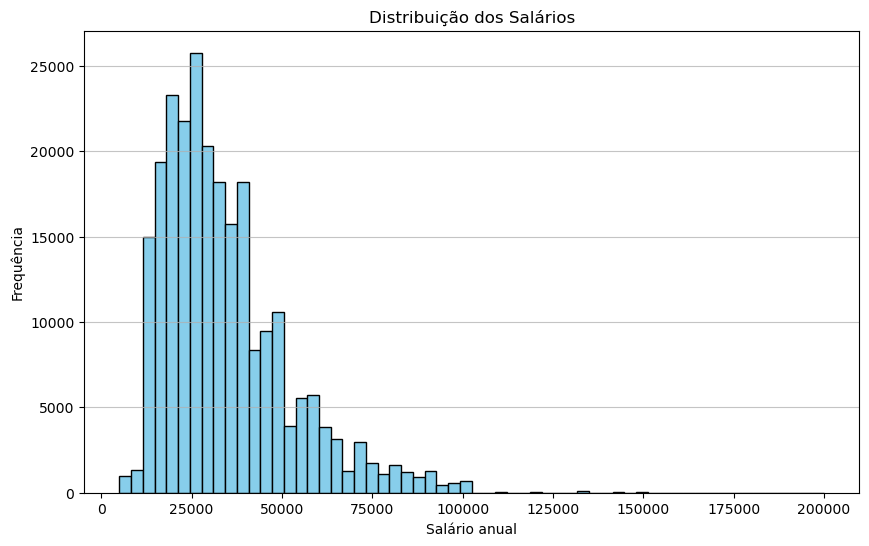

In [64]:

plt.figure(figsize=(10, 6))
plt.hist(df['salario'], bins=60, color='skyblue', edgecolor='black')
plt.title('Distribuição dos Salários')
plt.xlabel('Salário anual')
plt.ylabel('Frequência')
plt.grid(axis='y', alpha=0.75)
plt.show()

0.010     11520.0
0.050     13728.0
0.250     21500.0
0.500     30000.0
0.750     42500.0
0.950     70000.0
0.990     90000.0
0.995     96000.0
0.999    115000.0
Name: salario, dtype: float64
skew: 1.4155029656293558 | skew do log: 0.03161338887323377
== 200000: 8 | > 100000: 297 (0.12%)


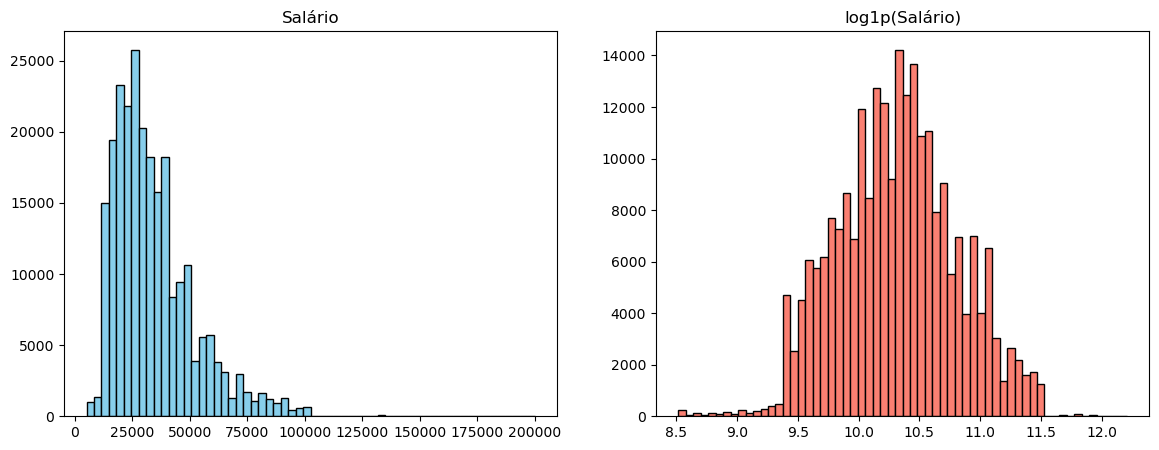

% múltiplos de 5000: 0.2727491859605257


In [ ]:


s = df['salario']
print(s.quantile([.01, .05, .25, .5, .75, .95, .99, .995, .999]))
print("skew:", s.skew(), "| skew do log:", np.log1p(s).skew())
print("== 200000:", (s == 200000).sum(), "| > 100000:", (s > 100000).sum(), f"({(s > 100000).mean():.2%})")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].hist(s, bins=60, color='skyblue', edgecolor='k'); ax[0].set_title('Salário')
ax[1].hist(np.log1p(s), bins=60, color='salmon', edgecolor='k'); ax[1].set_title('log1p(Salário)')
plt.show()

# salários redondos (múltiplos de 5000)
print("% múltiplos de 5000:", (s % 5000 == 0).mean())

In [66]:
cols = ['titulo','categoria','localizacao','empresa','fonte','salario']

print("== Top 200k ==")
print(df[df['salario'] == 200000][cols].to_string())

print("\n== 15 maiores abaixo de 200k ==")
print(df[df['salario'] < 200000].nlargest(15, 'salario')[cols].to_string())

print("\n== Menores salários ==")
print(df.nsmallest(20, 'salario')[cols].to_string())

# % de múltiplos de 5000 (você ainda não enviou esse resultado)
print("\n% múltiplos de 5000:", (df['salario'] % 5000 == 0).mean())

== Top 200k ==
                                                                                                       titulo                  categoria        localizacao                   empresa              fonte  salario
26213                                      Senior Strategic Asset Allocation specialist  Fiduciary/MultiAsset  Accounting & Finance Jobs             London                 IPS Group  eFinancialCareers   200000
28484   UK Barrister/Solicitor with Higher Rights (**** PQE) – BVI – Cross Border Work – Phenomenal Lifestyle                 Legal Jobs                 UK            Offshore Legal  legalweekjobs.com   200000
46482                                                                           PRIVATE CLIENT PARTNER LONDON                 Legal Jobs           The City        RedLaw Recruitment  legalweekjobs.com   200000
62965                                  C++ Trading Developer Hedge Fund  (High Frequency / C++ / STL / Boost)  Accounting & Finance Jobs         

                                                                                                  titulo                  categoria     localizacao                                     empresa                fonte  salario
16640                                                                         Reconciliations Accountant  Accounting & Finance Jobs          London                        Circle Square Talent              GAAPweb   199680
155955                                                                                        Accountant  Accounting & Finance Jobs  Cambridgeshire                   Pure Resourcing Solutions              GAAPweb   199200
46622                                                                                       PMO ****/day           Consultancy Jobs        The City                           Huxley Associates    gojobsearch.co.uk   192000
79298                                                       Programme Manager  Payments Jobs In Scotland  Health

In [67]:
# 1) Tamanho do piso em 5000
piso = df[df['salario'] == 5000]
print("n == 5000:", len(piso), f"({len(piso)/len(df):.3%})")
print(piso['fonte'].value_counts().head(10))
print(piso['categoria'].value_counts().head(10))

# 2) Outliers por categoria (IQR no log)
df['log_sal'] = np.log1p(df['salario'])
g = df.groupby('categoria')['log_sal']
q1, q3 = g.transform(lambda x: x.quantile(.25)), g.transform(lambda x: x.quantile(.75))
iqr = q3 - q1
df['out_cat'] = (df['log_sal'] > q3 + 3*iqr) | (df['log_sal'] < q1 - 3*iqr)
print("outliers por categoria:", df['out_cat'].sum())
print(df[df['out_cat']].groupby(['categoria','fonte']).size().sort_values(ascending=False).head(15))

# 3) Qualidade do alvo por fonte
print(df.groupby('fonte')['salario'].agg(['count','median','mean','min','max']).sort_values('count', ascending=False))

n == 5000: 31 (0.013%)
fonte
nijobs.com             9
strike-jobs.co.uk      9
Jobs Ac                4
totaljobs.com          3
MyUkJobs               2
Jobcentre Plus         1
jobsite.co.uk          1
jobs.guardian.co.uk    1
cwjobs.co.uk           1
Name: count, dtype: int64
categoria
Healthcare & Nursing Jobs           5
Teaching Jobs                       5
IT Jobs                             5
Customer Services Jobs              3
Accounting & Finance Jobs           2
Admin Jobs                          2
PR, Advertising & Marketing Jobs    2
Creative & Design Jobs              2
Other/General Jobs                  1
Energy, Oil & Gas Jobs              1
Name: count, dtype: int64
outliers por categoria: 72
categoria                    fonte            
Customer Services Jobs       totaljobs.com        10
IT Jobs                      totaljobs.com         7
                             Jobcentre Plus        7
Part time Jobs               Elance                6
Engineering Jobs  

In [68]:
suspeitos = df[df['out_cat'] & (df['salario'] > 100000)]
print(len(suspeitos))
print(suspeitos[['titulo','categoria','fonte','salario']].sort_values('salario', ascending=False).head(30).to_string())

9
                                                                     titulo                    categoria                           fonte  salario
227870                                                Office / Admin  Erith                   Admin Jobs                  Jobcentre Plus   192000
96761            Senior Drilling Engineer  Operator  Contract  Get in touch             Engineering Jobs                  OilCareers.com   192000
19383                                                   FT Application Lead                  Travel Jobs             jobs.guardian.co.uk   180000
76018                                                  Gate House Attendant                   Admin Jobs                  Jobcentre Plus   180000
36145                                     Fitness Instructor Apprenticeship                Teaching Jobs                  Jobcentre Plus   152640
229405                             Female Fitness Instructor Apprenticeship                Teaching Jobs                  

In [69]:
ids_remover = [227870, 76018, 36145, 229405, 63005, 19383]  
mask = (df['salario'] == 5000) | df.index.isin(ids_remover)
print("removendo:", mask.sum())
df = df[~mask].copy()

removendo: 37


## Data Leakage

- Foram buscados números no texto próximos ao alvo (±10%): **17 casos no título e 1.139 na descrição (0,47%)**.
- A base já veio parcialmente mascarada (`****`), mas o texto ainda contém números.
- Esse valor é uma ordem de grandeza: regex não captura faixas escritas de outras formas e coincidências são possíveis.
- **Decisão:** mascarar números e valores monetários em `titulo` e `descricao` antes de vetorizar, mantendo o texto original para auditoria. O impacto será medido na modelagem, comparando o mesmo modelo com e sem máscara.


In [70]:
def extrai_candidatos(texto):
    if pd.isnull(texto): return []
    vals = []
    # 30k, 25K, 30-35k
    for m in re.finditer(r'(\d{2,3})\s?[kK]\b', texto):
        vals.append(int(m.group(1)) * 1000)
    # 30,000 / 30.000
    for m in re.finditer(r'\b(\d{2,3})[.,](\d{3})\b', texto):
        vals.append(int(m.group(1)) * 1000 + int(m.group(2)))
    # £30000 / £ 30000
    for m in re.finditer(r'£\s?(\d{4,6})\b', texto):
        vals.append(int(m.group(1)))
    return [v for v in vals if 5000 <= v <= 200000]

def bate_com_alvo(row, col, tol=0.10):
    cands = extrai_candidatos(row[col])
    return any(abs(c - row['salario']) / row['salario'] <= tol for c in cands)

df['leak_titulo'] = df.apply(lambda r: bate_com_alvo(r, 'titulo'), axis=1)
df['leak_desc']   = df.apply(lambda r: bate_com_alvo(r, 'descricao'), axis=1)
print("título bate com alvo (±10%):", df['leak_titulo'].sum())
print("descrição bate com alvo (±10%):", df['leak_desc'].sum())

título bate com alvo (±10%): 17
descrição bate com alvo (±10%): 1139


## Análise por segmento

- **`categoria`** (29 níveis): feature forte. A mediana vai de 7.500 (Part time) a 40.000 (IT, Energy). Dentro de cada categoria o desvio é alto (10k a 23k), então o texto e a localização devem agregar.
- **`localizacao`** (2.732 níveis): efeito geográfico claro (The City 42.500, London 39.000, interior entre 23k e 28k). O valor `UK` representa 16,8% da base e não informa região. Várias categorias são, na prática, Londres.
- **`localizacao_original`** (20.984 níveis): quase texto livre, **não usar como categórica**.
- **`empresa`** (20.806 níveis): alta cardinalidade; usar target encoding suavizado dentro de cada fold.
- **`fonte`**: a mediana varia muito (Jobcentre Plus 16.500, cwjobs 43.500), então é feature relevante. Das 168 fontes, 116 têm 100+ anúncios; as 52 raras (1.641 linhas, 0,7%) foram agrupadas em `others`.
- `Maintenance Jobs` é uma categoria mal nomeada (faxineiros e técnicos), mas com salários coerentes: mantida. `Part time Jobs` (145 linhas) tem salários incoerentes com os cargos: mantida e monitorada na avaliação de erro.


In [71]:
print(df.groupby('categoria')['salario'].agg(['count','median','mean','std']).sort_values('median', ascending=False))

top_loc = df['localizacao'].value_counts().head(20).index
print(df[df['localizacao'].isin(top_loc)].groupby('localizacao')['salario'].agg(['count','median']).sort_values('median', ascending=False))

print(df.groupby(df['tipo_contrato'].eq('unknown'))['salario'].agg(['count','median','mean']))
print(df.groupby(df['regime_contrato'].eq('unknown'))['salario'].agg(['count','median','mean']))

print(df[['empresa','localizacao','localizacao_original','categoria','fonte']].nunique())

                                  count   median          mean           std
categoria                                                                   
Energy, Oil & Gas Jobs             2254  40000.0  45671.128660  20481.312529
IT Jobs                           38478  40000.0  43988.977130  18237.214646
Legal Jobs                         3939  37500.0  42649.001015  23272.382331
Accounting & Finance Jobs         21844  34500.0  38754.305301  20537.376126
Consultancy Jobs                   3263  32500.0  37028.871591  18536.937170
Trade & Construction Jobs          8836  32500.0  36410.216501  17395.857049
PR, Advertising & Marketing Jobs   8852  32500.0  35600.699164  15733.184831
Engineering Jobs                  25174  32500.0  35838.268332  14598.501046
Scientific & QA Jobs               2489  31000.0  34436.930896  16093.092679
Other/General Jobs                17054  30000.0  35348.213440  19667.956287
Property Jobs                      1038  30000.0  32512.806358  13932.870223

In [72]:
vc = df['fonte'].value_counts()
print((vc >= 100).sum(), "fontes com >=100 |", vc[vc < 100].sum(), "linhas nas demais")
print(df[df['categoria'].isin(['Part time Jobs', 'Maintenance Jobs'])]
        [['titulo', 'categoria', 'salario']].sample(15, random_state=1).to_string())

116 fontes com >=100 | 1641 linhas nas demais
                                                                                                    titulo         categoria  salario
74265                                                                                   Cleaning Operative  Maintenance Jobs    11904
11777                                                                                 Operations Associate  Maintenance Jobs    11904
14982                                                                                       HGV Technician  Maintenance Jobs    21120
36994                                                                                    Part Time Cleaner  Maintenance Jobs    12000
98510                                                                                Mobile Phone Engineer  Maintenance Jobs    15360
20238                                                                                       OFFICE CLEANER  Maintenance Jobs    11904
132997          

## Analise do Texto

- Descrição: mediana de 226 palavras, P99 de 651, máximo de 2.113. Título: mediana de 4 palavras.
- 237 descrições com menos de 20 palavras e 49 com HTML/entidades (limpeza simples).
- Correlação de Spearman entre tamanho da descrição e salário: 0,13 (fraca, útil como feature auxiliar).


In [73]:
df['len_desc'] = df['descricao'].str.split().str.len()
df['len_tit'] = df['titulo'].fillna('').str.split().str.len()
print(df[['len_desc', 'len_tit']].describe(percentiles=[.01, .5, .99]))
print("descrições < 20 palavras:", (df['len_desc'] < 20).sum())
print("com HTML/entidades:", df['descricao'].str.contains(r'<[a-z]+|&[a-z]+;', regex=True).sum())
print(df[['len_desc', 'salario']].corr(method='spearman'))

            len_desc        len_tit
count  244730.000000  244730.000000
mean      244.842676       4.213844
std       130.214529       2.238541
min         4.000000       1.000000
1%         37.000000       1.000000
50%       226.000000       4.000000
99%       651.000000      11.000000
max      2113.000000      24.000000
descrições < 20 palavras: 237
com HTML/entidades: 49
          len_desc   salario
len_desc  1.000000  0.128218
salario   0.128218  1.000000


## Decisões Para Modelagem

| Tema | Decisão |
|---|---|
| Alvo | `log1p(salario)`; métrica principal MAE (+ RMSE e RMSLE) |
| Split | 80/20, agrupado por hash do texto, estratificado por faixas do alvo, seed fixa |
| Leakage | Máscara de números no texto + teste de sanidade com/sem máscara |
| Categóricas | One-hot (`categoria`, `tipo_contrato`, `regime_contrato`, `fonte`); target encoding (`empresa`, `localizacao`) dentro do fold |
| Localização | Criar feature de região; tratar `UK` como categoria própria |
| Texto | TF-IDF (título e descrição separados) + embeddings como segunda etapa |
| Modelos | Baseline pela mediana, Ridge, LightGBM (perda robusta), ensemble |
| Ruído de rótulo | Reportar MAE e mediana do erro absoluto; analisar erro por categoria e faixa |

## Salvando Df

In [74]:
df = df.drop(columns=[
    'log_sal',
    'out_cat',
    'salario_no_titulo',
    'salario_na_descricao',
    'leak_titulo',
    'leak_desc',
    'len_desc',
    'len_tit'
], errors='ignore')

In [75]:
df.head()

,id_anuncio,titulo,descricao,localizacao_original,localizacao,tipo_contrato,regime_contrato,empresa,categoria,salario,fonte,tipo_contrato_missing,regime_contrato_missing,empresa_missing
0,1,Business Account Manager,Business Account Manager Plumbing Heating Pro...,South West,South West London,unknown,permanent,BMS Sales Specialists,Sales Jobs,23500,totaljobs.com,1,0,0
1,2,Staff Nurse RGN/RMN Newtown Abbey Nights Ne...,Job Title; Staff Nurse RGN/RMN – NightsLocatio...,Newtownabbey,Newtownabbey,full_time,unknown,Regional Recruitment Services,Healthcare & Nursing Jobs,23040,staffnurse.com,0,1,0
2,3,Community Fundraising Manager,This dynamic international development charity...,London,London,full_time,permanent,TPP Not for Profit,Charity & Voluntary Jobs,34850,Third Sector Jobs,0,0,0
3,4,Conveyancing Executive,Large regional law firm require a residential ...,Hampshire,Hampshire,full_time,permanent,PTP Consulting,Legal Jobs,22500,TotallyLegal,0,0,0
4,5,Investment Compliance Analyst,This individual will work closely with the bus...,London South East,South East London,unknown,permanent,Michael Page Financial Services,Accounting & Finance Jobs,55000,totaljobs.com,1,0,0


In [76]:
df.to_csv('../../data/processed/base_vagas.csv', index=False)